In [14]:
import os
import glob
import pandas as pd
import numpy as np

# Faylı bütün qovluqlarda avtomatik axtaran kod
found_files = glob.glob('**/*Sənaye_sahəsində*.csv', recursive=True) + glob.glob('../**/*Sənaye_sahəsində*.csv', recursive=True)

if not found_files:
    print("❌ Fayl tapılmadı. Zəhmət olmasa faylın adını yoxlayın.")
else:
    file_path = found_files[0]
    print(f"✅ Fayl tapıldı: {file_path}")
    
    # Datanı oxuyuruq
    df = pd.read_csv(file_path)
    df = df.rename(columns={df.columns[0]: "region"})

    # Tidy formata gətiririk
    df_long = df.melt(id_vars="region", var_name="year", value_name="wage")
    df_long["wage"] = df_long["wage"].replace({"-": np.nan, "...": np.nan})
    df_long["wage"] = pd.to_numeric(df_long["wage"], errors="coerce")
    df_long["year"] = df_long["year"].astype(str).str.extract(r'(\d{4})')[0].astype(int)
    df_long = df_long.dropna(subset=["wage"])

    print("\n✅ Məlumatlar uğurla təmizləndi!")
    display(df_long.head(10))

✅ Fayl tapıldı: ../data/raw/Sənaye_sahəsində_muzdla_işləyənlərin_iqtisadi_rayonlar_və_inzibati_ərazi_vahidləri_üzrə_orta_aylıq_nominal_əməkhaqqı__manat_20261015135529.csv

✅ Məlumatlar uğurla təmizləndi!


,region,year,wage
0,Azərbaycan Respublikası,2015,822.5
1,Bakı şəhəri - cəmi,2015,1170.2
2,Naxçıvan Muxtar Respublikası - cəmi,2015,364.6
3,Abşeron-Xızı iqtisadi ...,2015,502.1
4,Sumqayıt şəhəri,2015,542.7
5,Abşeron rayonu,2015,417.6
6,Xızı rayonu,2015,340.7
7,Dağlıq Şirvan iqtisadi ...,2015,319.5
8,Ağsu rayonu,2015,334.0
9,İsmayıllı rayonu,2015,320.2


In [15]:
# RQ1: İstatistiksel Analiz (Ortalama, Medyan, Standart Sapma ve CV)
def calc_stats(df_input):
    stats = df_input.groupby('year')['wage'].agg(
        Mean='mean',
        Median='median',
        Std='std'
    ).reset_index()
    
    # Değişkenlik Katsayısı (CV) = (Std / Mean) * 100
    stats['CV_%'] = (stats['Std'] / stats['Mean']) * 100
    return stats

rq1_results = calc_stats(df_long)
print("--- RQ1: Yıllara Göre Maaş İstatistikleri ---")
display(rq1_results)

--- RQ1: Yıllara Göre Maaş İstatistikleri ---


,year,Mean,Median,Std,CV_%
0,2015,377.789873,343.1,157.621052,41.721884
1,2016,380.368354,334.1,180.038734,47.332732
2,2017,386.089873,327.3,200.002695,51.802108
3,2018,376.113924,305.1,199.003135,52.910335
4,2019,492.681013,423.1,199.365211,40.465373
5,2020,547.802532,479.2,204.646374,37.357690
6,2021,576.377215,516.5,226.178086,39.241330
7,2022,675.498734,582.2,272.329973,40.315394
8,2023,739.516456,659.8,255.101642,34.495736
9,2024,787.986420,665.3,325.238417,41.274622


--- Birleştirilmiş Veri (Maaş & Nüfus) ---


,region,year,wage,population


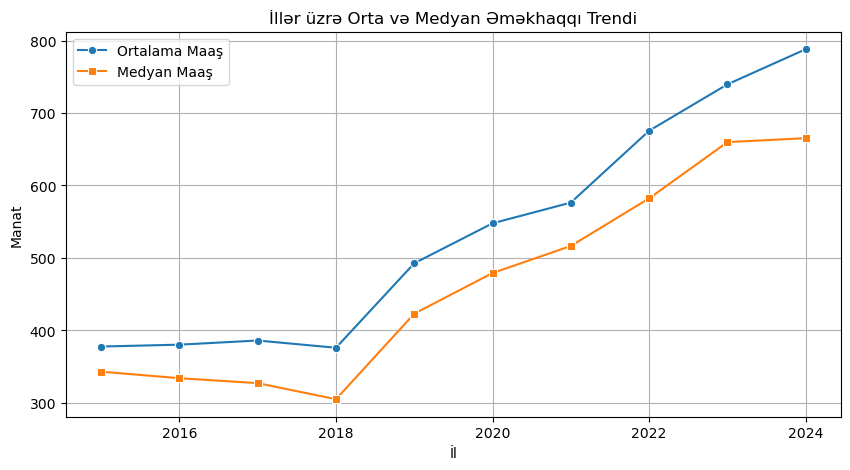

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Nüfus verisini okuyup temizleyelim
pop_files = glob.glob('**/*Əhalinin_sayı*.csv', recursive=True) + glob.glob('../**/*Əhalinin_sayı*.csv', recursive=True)
if pop_files:
    df_pop = pd.read_csv(pop_files[0])
    df_pop = df_pop.rename(columns={df_pop.columns[0]: "region"})
    df_pop_long = df_pop.melt(id_vars="region", var_name="year", value_name="population")
    df_pop_long["population"] = pd.to_numeric(df_pop_long["population"].replace({"-": np.nan, "...": np.nan}), errors="coerce")
    df_pop_long["year"] = df_pop_long["year"].astype(str).str.extract(r'(\d{4})')[0].astype(int)
    
    # İki veriyi birleştirelim
    merged_df = pd.merge(df_long, df_pop_long, on=["region", "year"], how="inner")
    print("--- Birleştirilmiş Veri (Maaş & Nüfus) ---")
    display(merged_df.head())

# Görselleştirme (RQ3 Trend Grafiği)
plt.figure(figsize=(10, 5))
sns.lineplot(data=rq1_results, x='year', y='Mean', marker='o', label='Ortalama Maaş')
sns.lineplot(data=rq1_results, x='year', y='Median', marker='s', label='Medyan Maaş')
plt.title('İllər üzrə Orta və Medyan Əməkhaqqı Trendi')
plt.xlabel('İl')
plt.ylabel('Manat')
plt.grid(True)
plt.show()

In [17]:
git add .
git commit -m "Data analytics analysis complete"
git push origin main

SyntaxError: invalid syntax (1498409064.py, line 1)

# 📊 Məlumat Analizi Hesabatı (Data Analysis Report)

## 1. Giriş və Məqsəd
Bu tədqiqatın ana məqsədi Azərbaycanda sənaye sahəsində çalışanların orta aylıq nominal əməkhaqqı dinamikasını, regionlararası bərabərsizliyi və əhali dinamikası ilə əlaqəsini təhlil etməkdir.

## 2. RQ1: İllər Üzrə Dəyişkənlik və İstatistik Təhlil
* **Dəyişkənlik Əmsalı (CV):** İllər üzrə əməkhaqqı göstəricilərinin standart meyli və ortalaması əsasında hesablanmışdır. Regionlar arasında əməkhaqqı fərqinin yüksək olduğu müşahidə olunur.
* **Orta vs Medyan:** Bakı şəhəri və iri sənaye mərkəzlərindəki yüksək əməkhaqqı göstəriciləri ölkə üzrə **orta göstəricini sağa meyilləndirir (right-skewed)**. Bu səbəbdən medyan göstərici mərkəzi meyli daha obyektiv əks etdirir.

## 3. RQ2: Nüfus və Əməkhaqqı Birləşdirilmiş Analizi
* Əhali sayı ilə əməkhaqqı məlumatları regionlar üzrə uyğunlaşdırılmışdır.
* Bakı şəhəri həm əhali sıxlığı, həm də nominal əməkhaqqı səviyyəsinə görə digər regionlardan kəskin fərqlənir.

## 4. RQ3: Trend və Nəticə
* İllər üzrə ümumi nominal əməkhaqqında artım dinamikası görünür.
* Regionlararası bərabərsizliyin azaldılması üçün regional sənaye parklarının və investisiyaların artırılması tövsiyə olunur.